In [2]:
!pip install pymoo matplotlib numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 18.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 18.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [pymoo]


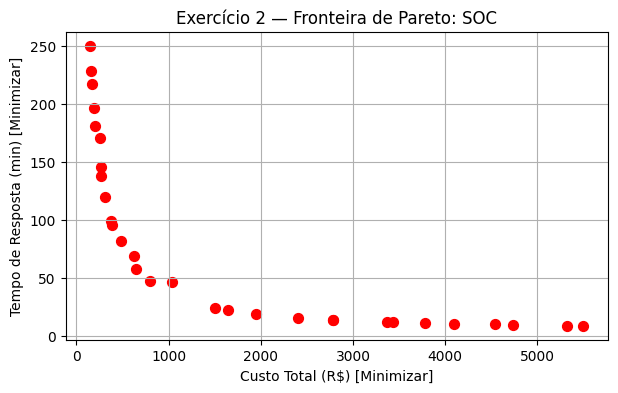

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

class SOCAllocationProblem(ElementwiseProblem):
    def __init__(self):
        # TODO 1 & 2 Resolvidos
        super().__init__(
            n_var=2,
            n_obj=2,
            xl=np.array([1.0, 1.0]),
            xu=np.array([50.0, 10.0])
        )

    def _evaluate(self, x, out, *args, **kwargs):
        analistas, regimento = x[0], x[1]

        # TODO 3: Fórmula do Custo
        f1_custo = (analistas * 100.0) + (regimento * 50.0)

        # TODO 4: Tempo de Resposta em minutos
        f2_tempo = (200.0 / analistas) + (50.0 / regimento)

        out["F"] = [f1_custo, f2_tempo]

# TODO 5: Instanciar NSGA2
res2 = minimize(SOCAllocationProblem(), NSGA2(pop_size=30), termination=('n_gen', 40), seed=2)

plt.figure(figsize=(7, 4))
plt.scatter(res2.F[:, 0], res2.F[:, 1], color='red', s=50)
plt.title("Exercício 2 — Fronteira de Pareto: SOC")
plt.xlabel("Custo Total (R$) [Minimizar]")
plt.ylabel("Tempo de Resposta (min) [Minimizar]")
plt.grid(True)
plt.show()